###  ML Experiment Number 10





### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

# Task 1: Import Libraries and Load Dataset

# Step 1: Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Step 2: Load the Mall Customer Segmentation dataset
url = "https://raw.githubusercontent.com/kennedykwangari/Mall-Customer-Segmentation-Data/master/Mall_Customers.csv"

df = pd.read_csv(url)

# Step 3: Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Step 4: Display dataset information
print("\nDataset Information:")
df.info()

# Step 5: Display the number of rows and columns
print("\nDataset Shape:", df.shape)

# Step 6: Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Step 7: Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Step 8: Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# Step 9: Display library versions
print("\nLibrary Versions:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nDataset loaded successfully!")


First five rows of the dataset:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Statistical Summary:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000



Library Versions:
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1

Dataset loaded successfully!


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:

# Task 2: Feature Selection and Standardization

# Step 1: Import required libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Step 2: Load the dataset if it is not already loaded
if "df" not in globals():
    url = "https://raw.githubusercontent.com/kennedykwangari/Mall-Customer-Segmentation-Data/master/Mall_Customers.csv"
    df = pd.read_csv(url)

# Step 3: Select the required features
features = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[features].copy()

# Step 4: Handle missing values
X = X.dropna().copy()

# Step 5: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert the scaled data back to a DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

# Step 6: Display original features
print("Original Features:")
display(X.head())

# Step 7: Display standardized features
print("\nStandardized Features:")
display(X_scaled.head())

# Step 8: Verify the standardized data
print("\nMean of standardized features:")
print(X_scaled.mean().round(4))

print("\nStandard deviation of standardized features:")
print(X_scaled.std(ddof=0).round(4))

print("\nShape of standardized dataset:", X_scaled.shape)

print("\nFeature selection and standardization completed successfully!")


Original Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Standardized Features:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Mean of standardized features:
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Standard deviation of standardized features:
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64

Shape of standardized dataset: (200, 2)

Feature selection and standardization completed successfully!


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

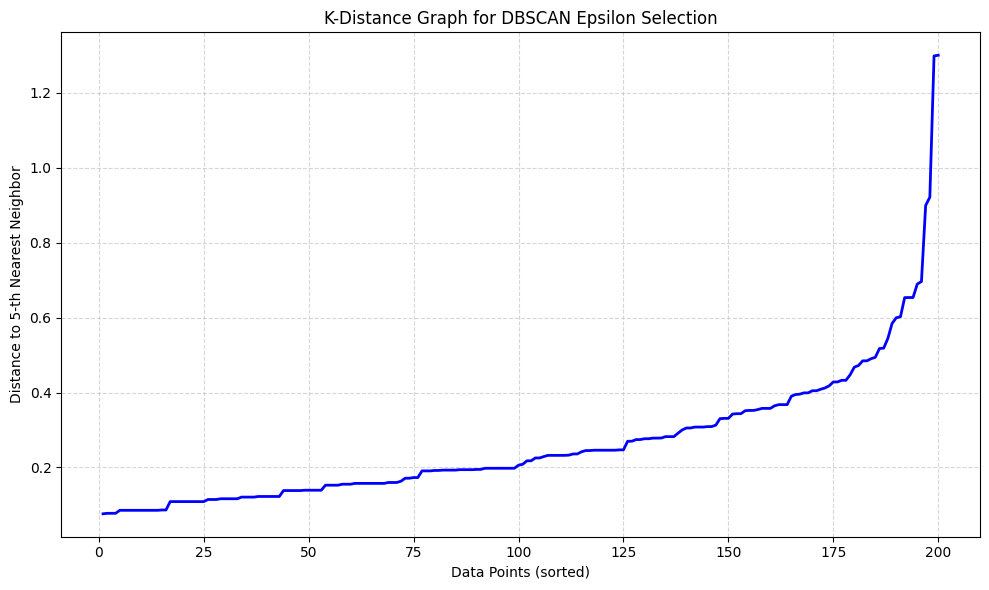

Dataset loaded successfully.
Number of data points: 200
min_samples: 5
90th percentile distance: 0.4682
95th percentile distance: 0.5996

Choose eps approximately at the elbow of the plotted curve.


In [ ]:

# Task 3: Hyperparameter Selection via k-Distance Graph

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# Step 2: Load the Mall Customers dataset
url = "https://raw.githubusercontent.com/kennedykwangari/Mall-Customer-Segmentation-Data/master/Mall_Customers.csv"
df = pd.read_csv(url)

# Step 3: Select features
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].dropna()

# Step 4: Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Set min_samples
min_samples = 5

# Step 6: Compute nearest-neighbor distances
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Get distance to the k-th nearest neighbor
k_distances = distances[:, min_samples - 1]

# Step 7: Sort distances in ascending order
k_distances_sorted = np.sort(k_distances)

# Step 8: Plot the k-distance graph
plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(k_distances_sorted) + 1),
    k_distances_sorted,
    color="blue",
    linewidth=2
)

plt.xlabel("Data Points (sorted)")
plt.ylabel(f"Distance to {min_samples}-th Nearest Neighbor")
plt.title("K-Distance Graph for DBSCAN Epsilon Selection")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Step 9: Print useful information
print("Dataset loaded successfully.")
print("Number of data points:", len(X_scaled))
print("min_samples:", min_samples)
print("90th percentile distance:", round(float(np.percentile(k_distances_sorted, 90)), 4))
print("95th percentile distance:", round(float(np.percentile(k_distances_sorted, 95)), 4))

print("\nChoose eps approximately at the elbow of the plotted curve.")


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

DBSCAN clustering completed successfully!

Epsilon (eps): 0.3
Minimum samples: 5

Cluster labels found:
[-1  0  1  2  3  4  5  6]

Number of clusters (excluding noise): 7
Number of noise points: 35

Number of customers in each cluster:
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

First five clustering results:


,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,2
1,15,81,0
2,16,6,1
3,16,77,0
4,17,40,2


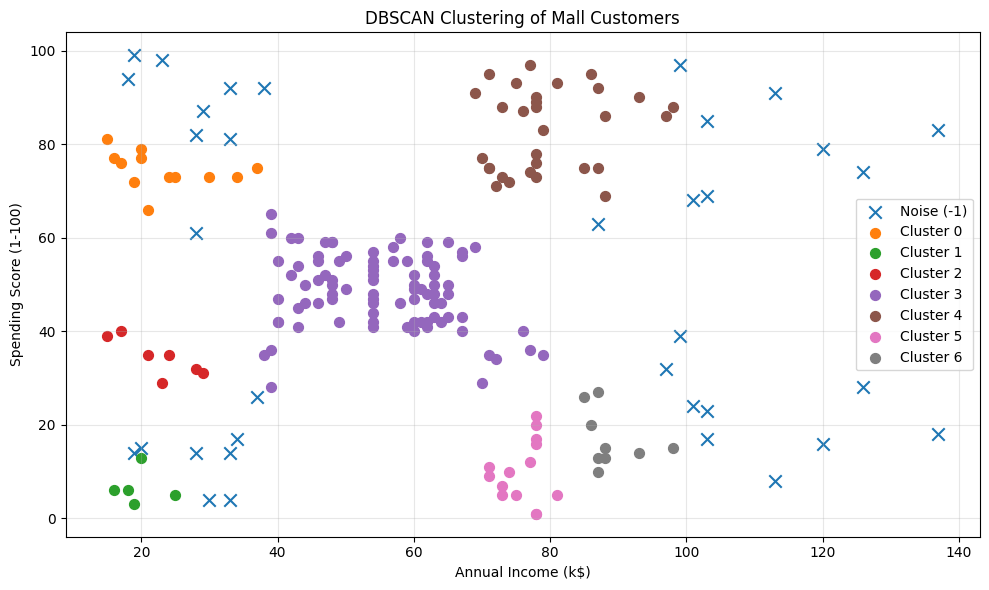


Task 4 completed successfully!


In [ ]:

# Task 4: Implement DBSCAN Clustering

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# Step 2: Load the Mall Customers dataset
url = "https://raw.githubusercontent.com/kennedykwangari/Mall-Customer-Segmentation-Data/master/Mall_Customers.csv"
df = pd.read_csv(url)

# Step 3: Select the required features
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].dropna().copy()

# Step 4: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Set DBSCAN hyperparameters
# Replace eps with the value identified from your Task 3 k-distance graph.
eps_value = 0.3
min_samples_value = 5

# Step 6: Create and fit the DBSCAN model
dbscan_model = DBSCAN(
    eps=eps_value,
    min_samples=min_samples_value
)

cluster_labels = dbscan_model.fit_predict(X_scaled)

# Step 7: Store cluster assignments
X["Cluster"] = cluster_labels

# Step 8: Display clustering results
print("DBSCAN clustering completed successfully!")
print("\nEpsilon (eps):", eps_value)
print("Minimum samples:", min_samples_value)

print("\nCluster labels found:")
print(np.unique(cluster_labels))

print("\nNumber of clusters (excluding noise):",
      len(set(cluster_labels) - {-1}))

print("Number of noise points:",
      int(np.sum(cluster_labels == -1)))

print("\nNumber of customers in each cluster:")
print(X["Cluster"].value_counts().sort_index())

print("\nFirst five clustering results:")
display(X.head())

# Step 9: Visualize the clusters
plt.figure(figsize=(10, 6))

for label in sorted(np.unique(cluster_labels)):
    cluster_data = X[X["Cluster"] == label]

    if label == -1:
        plt.scatter(
            cluster_data["Annual Income (k$)"],
            cluster_data["Spending Score (1-100)"],
            label="Noise (-1)",
            marker="x",
            s=80
        )
    else:
        plt.scatter(
            cluster_data["Annual Income (k$)"],
            cluster_data["Spending Score (1-100)"],
            label=f"Cluster {label}",
            s=50
        )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN Clustering of Mall Customers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTask 4 completed successfully!")


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Task 5: Evaluate DBSCAN Clustering

# Step 1: Import required libraries
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Step 2: Load the Mall Customers dataset
url = "https://raw.githubusercontent.com/kennedykwangari/Mall-Customer-Segmentation-Data/master/Mall_Customers.csv"
df = pd.read_csv(url)

# Step 3: Select features and handle missing values
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].dropna().copy()

# Step 4: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Set DBSCAN parameters
# Adjust eps based on the elbow in your Task 3 k-distance graph.
eps_value = 0.3
min_samples_value = 5

# Step 6: Fit the DBSCAN model
dbscan_model = DBSCAN(
    eps=eps_value,
    min_samples=min_samples_value
)

cluster_labels = dbscan_model.fit_predict(X_scaled)

# Step 7: Count clusters and noise points
unique_labels = set(cluster_labels)

# Exclude -1 (noise) from the cluster count
n_clusters = len(unique_labels - {-1})

# Count noise points
n_noise = int(np.sum(cluster_labels == -1))

total_points = len(cluster_labels)
noise_percentage = (n_noise / total_points) * 100 if total_points else 0

print("=" * 45)
print("DBSCAN CLUSTERING EVALUATION")
print("=" * 45)

print("Total data points:", total_points)
print("Number of clusters (excluding noise):", n_clusters)
print("Number of noise points:", n_noise)
print(f"Noise percentage: {noise_percentage:.2f}%")

# Step 8: Display cluster sizes
print("\nCluster sizes:")
for label in sorted(unique_labels):
    count = int(np.sum(cluster_labels == label))

    if label == -1:
        print(f"Noise (-1): {count} points")
    else:
        print(f"Cluster {label}: {count} points")

# Step 9: Calculate Silhouette Score
# Exclude noise points from the score so it evaluates formed clusters.
non_noise_mask = cluster_labels != -1
X_clustered = X_scaled[non_noise_mask]
labels_clustered = cluster_labels[non_noise_mask]

n_assigned = len(labels_clustered)
n_assigned_clusters = len(set(labels_clustered))

print("\nSilhouette Score Analysis:")

if n_assigned_clusters >= 2 and n_assigned > n_assigned_clusters:
    score = silhouette_score(X_clustered, labels_clustered)
    print(f"Silhouette Score (excluding noise): {score:.4f}")
    print("Score range: -1 to +1")
    print("Higher scores generally indicate better-separated clusters.")
else:
    print(
        "Silhouette Score cannot be calculated reliably: "
        "DBSCAN must assign at least two clusters, with enough "
        "non-noise samples for the calculation."
    )

print("\nEvaluation completed successfully!")


DBSCAN CLUSTERING EVALUATION
Total data points: 200
Number of clusters (excluding noise): 7
Number of noise points: 35
Noise percentage: 17.50%

Cluster sizes:
Noise (-1): 35 points
Cluster 0: 12 points
Cluster 1: 5 points
Cluster 2: 7 points
Cluster 3: 88 points
Cluster 4: 30 points
Cluster 5: 14 points
Cluster 6: 9 points

Silhouette Score Analysis:
Silhouette Score (excluding noise): 0.5243
Score range: -1 to +1
Higher scores generally indicate better-separated clusters.

Evaluation completed successfully!


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [ ]:

# Task 6: Analyze Results and Cluster Statistics

# Step 1: Import required libraries
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# Step 2: Load the Mall Customers dataset
url = "https://raw.githubusercontent.com/kennedykwangari/Mall-Customer-Segmentation-Data/master/Mall_Customers.csv"
df = pd.read_csv(url)

# Step 3: Select the required features
features = ["Annual Income (k$)", "Spending Score (1-100)"]

# Preserve original dataset and row indices
df_result = df.copy()

# Step 4: Handle missing values in the selected features
valid_mask = df_result[features].notna().all(axis=1)
X = df_result.loc[valid_mask, features].copy()

# Step 5: Standardize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 6: Apply DBSCAN
# Adjust eps based on the Task 3 k-distance graph
eps_value = 0.3
min_samples_value = 5

dbscan_model = DBSCAN(
    eps=eps_value,
    min_samples=min_samples_value
)

cluster_labels = dbscan_model.fit_predict(X_scaled)

# Step 7: Append cluster labels to the original dataset
df_result["Cluster"] = pd.Series(
    pd.NA,
    index=df_result.index,
    dtype="Int64"
)

df_result.loc[valid_mask, "Cluster"] = cluster_labels

print("Cluster labels added to the original dataset.")
print("\nFirst five rows with cluster labels:")
display(df_result.head())

# Step 8: Calculate cluster statistics
# Noise (-1) is included as a separate group for analysis.
cluster_stats = (
    df_result.loc[valid_mask]
    .groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Average_Annual_Income=("Annual Income (k$)", "mean"),
        Average_Spending_Score=("Spending Score (1-100)", "mean"),
        Minimum_Annual_Income=("Annual Income (k$)", "min"),
        Maximum_Annual_Income=("Annual Income (k$)", "max"),
        Minimum_Spending_Score=("Spending Score (1-100)", "min"),
        Maximum_Spending_Score=("Spending Score (1-100)", "max")
    )
    .round(2)
)

print("\nCluster Statistics (including noise):")
display(cluster_stats)

# Step 9: Analyze noise points
noise_data = df_result[df_result["Cluster"] == -1]

print("\nNoise Point Analysis")
print("-" * 35)
print("Number of noise points:", len(noise_data))

if len(noise_data) > 0:
    print("\nNoise point details:")
    display(
        noise_data[
            ["CustomerID", "Gender",
             "Annual Income (k$)", "Spending Score (1-100)"]
        ].head(10)
    )

    print("\nAverage statistics of noise points:")
    display(
        noise_data[
            ["Annual Income (k$)", "Spending Score (1-100)"]
        ].mean().to_frame(name="Noise Average").round(2)
    )
else:
    print("No noise points were detected.")

# Step 10: Display final summary
n_clusters = len(set(cluster_labels) - {-1})

print("\nFinal Summary")
print("-" * 35)
print("Total customers in original dataset:", len(df_result))
print("Customers clustered:", int(valid_mask.sum()))
print("Number of clusters (excluding noise):", n_clusters)
print("Number of noise points:", len(noise_data))

print("\nTask 6 completed successfully!")


Cluster labels added to the original dataset.

First five rows with cluster labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,0
2,3,Female,20,16,6,1
3,4,Female,23,16,77,0
4,5,Female,31,17,40,2



Cluster Statistics (including noise):


,Customer_Count,Average_Annual_Income,Average_Spending_Score,Minimum_Annual_Income,Maximum_Annual_Income,Minimum_Spending_Score,Maximum_Spending_Score
Cluster,,,,,,,
-1,35,70.60,51.66,18,137,4,99
0,12,23.17,74.58,15,37,66,81
1,5,19.60,6.60,16,25,3,13
2,7,22.43,34.43,15,29,29,40
3,88,55.23,48.58,38,79,28,65
4,30,79.53,83.13,69,98,69,97
5,14,75.93,10.07,71,81,1,22
6,9,88.78,17.00,85,98,10,27



Noise Point Analysis
-----------------------------------
Number of noise points: 35

Noise point details:


,CustomerID,Gender,Annual Income (k$),Spending Score (1-100)
7,8,Female,18,94
10,11,Male,19,14
11,12,Female,19,99
12,13,Female,20,15
19,20,Female,23,98
24,25,Female,28,14
25,26,Male,28,82
27,28,Male,28,61
29,30,Female,29,87
30,31,Male,30,4



Average statistics of noise points:


,Noise Average
Annual Income (k$),70.60
Spending Score (1-100),51.66



Final Summary
-----------------------------------
Total customers in original dataset: 200
Customers clustered: 200
Number of clusters (excluding noise): 7
Number of noise points: 35

Task 6 completed successfully!


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.